# Step 8 - Stability metrics

How much do the scores and rankings of each method move under damage? (Phase A, Sections 4.4, 4.7, 4.8)

- **Ranking stability** - Spearman and Kendall between the base ranking and each of the K = 30 perturbed rankings; mean, std and ranking instability (std / mean).
- **Top of the ranking** - Spearman over the method's own top 10 % only, and the share of the top-100 / top-1000 that stays in the top.
- **Node level** - coefficient of variation (CV) of each paper's score over the runs.
- **Instability profiles** - do the forest and a single measure become unstable on the same papers?

Logic: `src/stability.py`, `src/analysis.py`. Needs the runs of step 7 (`results/runs/`).

In [1]:
import os, sys
if 'google.colab' in sys.modules and not os.path.exists('Final-Project'):
    !git clone https://github.com/ShaharBar99/Final-Project.git
    %cd Final-Project
    !pip install -q -r requirements.txt
elif os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.getcwd())

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from src import analysis

per_run, cv_table, profiles, cvs = analysis.evaluate_all()
ranks = analysis.ranking_table(per_run)
analysis.TABLES_DIR.mkdir(parents=True, exist_ok=True)
per_run.to_csv(analysis.TABLES_DIR / 'per_run_correlations.csv', index=False)
ranks.to_csv(analysis.TABLES_DIR / 'ranking_stability.csv', index=False)
cv_table.to_csv(analysis.TABLES_DIR / 'cv_summary.csv', index=False)
profiles.to_csv(analysis.TABLES_DIR / 'instability_profiles.csv', index=False)
order = ['rf_without_pagerank', 'rf_with_pagerank', 'pagerank', 'closeness', 'degree', 'kcore', 'betweenness']
def show(metric):
    t = ranks.pivot_table(index='method', columns=['kind', 'level'], values=metric).loc[order]
    return t.round(3)

## 1. Global ranking stability - mean Spearman over 30 runs

(1 = the ranking did not move at all)

In [3]:
show('spearman_mean')

kind                add_dag               add_random               remove  \
level                  0.05   0.10   0.20       0.05   0.10   0.20   0.05   
method                                                                      
rf_without_pagerank   0.866  0.793  0.716      0.822  0.701  0.577  0.942   
rf_with_pagerank      0.850  0.700  0.535      0.793  0.600  0.389  0.965   
pagerank              0.876  0.785  0.667      0.830  0.703  0.525  0.965   
closeness             0.955  0.919  0.862      0.881  0.784  0.668  0.966   
degree                0.943  0.907  0.860      0.943  0.907  0.860  0.979   
kcore                 0.934  0.896  0.847      0.934  0.896  0.847  0.974   
betweenness           0.730  0.622  0.522      0.694  0.571  0.460  0.988   

kind                               
level                 0.10   0.20  
method                             
rf_without_pagerank  0.899  0.829  
rf_with_pagerank     0.931  0.861  
pagerank             0.931  0.861  
closeness            0.932  0.862  
degree               0.957  0.915  
kcore                0.947  0.897  
betweenness          0.975  0.949

## 2. Mean Kendall tau-b

In [4]:
show('kendall_mean')

kind                add_dag               add_random               remove  \
level                  0.05   0.10   0.20       0.05   0.10   0.20   0.05   
method                                                                      
rf_without_pagerank   0.768  0.664  0.568      0.709  0.568  0.460  0.886   
rf_with_pagerank      0.767  0.585  0.420      0.705  0.497  0.302  0.920   
pagerank              0.827  0.708  0.562      0.780  0.628  0.435  0.920   
closeness             0.908  0.842  0.753      0.804  0.674  0.539  0.942   
degree                0.917  0.863  0.794      0.917  0.863  0.794  0.963   
kcore                 0.912  0.859  0.793      0.912  0.859  0.793  0.955   
betweenness           0.710  0.591  0.478      0.667  0.533  0.411  0.985   

kind                               
level                 0.10   0.20  
method                             
rf_without_pagerank  0.817  0.723  
rf_with_pagerank     0.860  0.757  
pagerank             0.860  0.757  
closeness            0.890  0.795  
degree               0.929  0.867  
kcore                0.915  0.846  
betweenness          0.969  0.939

## 3. The same, but only over each method's own top 10 %

This removes the effect of large tied groups at the bottom (e.g. 90 % of papers have betweenness 0 in every run, which keeps the full correlation high).

In [5]:
show('spearman_top10pct_mean')

kind                add_dag               add_random               remove  \
level                  0.05   0.10   0.20       0.05   0.10   0.20   0.05   
method                                                                      
rf_without_pagerank   0.848  0.756  0.644      0.662  0.551  0.537  0.871   
rf_with_pagerank      0.826  0.722  0.608      0.842  0.735  0.607  0.939   
pagerank              0.826  0.722  0.608      0.842  0.735  0.607  0.939   
closeness             0.973  0.936  0.878      0.782  0.763  0.727  0.935   
degree                0.995  0.990  0.982      0.995  0.990  0.982  0.983   
kcore                 0.998  0.995  0.990      0.998  0.995  0.989  0.939   
betweenness           0.946  0.901  0.832      0.820  0.702  0.611  0.964   

kind                               
level                 0.10   0.20  
method                             
rf_without_pagerank  0.789  0.679  
rf_with_pagerank     0.883  0.782  
pagerank             0.883  0.782  
closeness            0.879  0.770  
degree               0.966  0.933  
kcore                0.914  0.891  
betweenness          0.929  0.860

## 4. Does the top survive? Share of the base top-100 still in the top-100

In [6]:
show('top100_kept')

kind                add_dag               add_random               remove  \
level                  0.05   0.10   0.20       0.05   0.10   0.20   0.05   
method                                                                      
rf_without_pagerank   0.803  0.685  0.643      0.662  0.529  0.454  0.880   
rf_with_pagerank      0.721  0.606  0.512      0.658  0.540  0.372  0.938   
pagerank              0.716  0.605  0.509      0.652  0.536  0.370  0.936   
closeness             0.886  0.842  0.788      0.687  0.698  0.666  0.946   
degree                1.000  0.999  0.979      1.000  0.999  0.982  0.975   
kcore                 0.967  1.000  1.000      1.000  1.000  1.000  0.451   
betweenness           0.818  0.720  0.611      0.313  0.230  0.263  0.922   

kind                               
level                 0.10   0.20  
method                             
rf_without_pagerank  0.818  0.696  
rf_with_pagerank     0.899  0.825  
pagerank             0.896  0.823  
closeness            0.909  0.860  
degree               0.947  0.913  
kcore                0.539  0.229  
betweenness          0.863  0.793

In [7]:
show('top1000_kept')

kind                add_dag               add_random               remove  \
level                  0.05   0.10   0.20       0.05   0.10   0.20   0.05   
method                                                                      
rf_without_pagerank   0.818  0.729  0.599      0.662  0.593  0.402  0.884   
rf_with_pagerank      0.517  0.448  0.390      0.471  0.355  0.269  0.937   
pagerank              0.517  0.448  0.390      0.471  0.355  0.269  0.937   
closeness             0.944  0.896  0.843      0.712  0.692  0.680  0.947   
degree                0.911  0.929  0.953      0.912  0.928  0.954  0.904   
kcore                 1.000  1.000  1.000      1.000  1.000  1.000  0.926   
betweenness           0.812  0.717  0.616      0.645  0.522  0.423  0.962   

kind                               
level                 0.10   0.20  
method                             
rf_without_pagerank  0.817  0.736  
rf_with_pagerank     0.895  0.826  
pagerank             0.895  0.826  
closeness            0.910  0.837  
degree               0.897  0.887  
kcore                0.871  0.902  
betweenness          0.932  0.886

## 5. Ranking instability (std / mean of Spearman over the runs)

Small numbers everywhere: the 30 runs of one setting agree with each other - the result is not a matter of a lucky seed.

In [8]:
show('spearman_instability')

kind                add_dag               add_random               remove  \
level                  0.05   0.10   0.20       0.05   0.10   0.20   0.05   
method                                                                      
rf_without_pagerank   0.004  0.005  0.006      0.010  0.011  0.010  0.003   
rf_with_pagerank      0.004  0.005  0.008      0.005  0.011  0.017  0.001   
pagerank              0.003  0.005  0.006      0.004  0.009  0.011  0.001   
closeness             0.003  0.004  0.003      0.008  0.010  0.011  0.002   
degree                0.001  0.001  0.001      0.001  0.001  0.002  0.001   
kcore                 0.001  0.001  0.002      0.001  0.001  0.002  0.001   
betweenness           0.003  0.003  0.002      0.004  0.005  0.004  0.002   

kind                               
level                 0.10   0.20  
method                             
rf_without_pagerank  0.004  0.004  
rf_with_pagerank     0.002  0.003  
pagerank             0.002  0.003  
closeness            0.002  0.003  
degree               0.001  0.001  
kcore                0.001  0.002  
betweenness          0.002  0.004

## 6. Plot - Spearman vs damage level

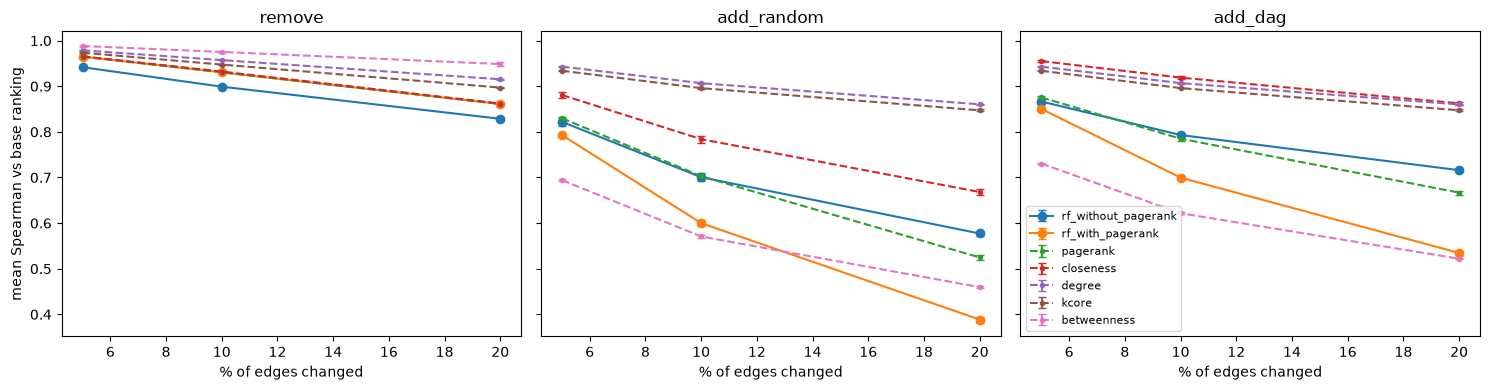

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, kind in zip(axes, ['remove', 'add_random', 'add_dag']):
    for m in order:
        t = ranks[(ranks.kind == kind) & (ranks.method == m)]
        style = '-o' if m.startswith('rf_') else '--.'
        ax.errorbar(t.level * 100, t.spearman_mean, yerr=t.spearman_std, fmt=style, label=m, capsize=3)
    ax.set_title(kind); ax.set_xlabel('% of edges changed')
axes[0].set_ylabel('mean Spearman vs base ranking')
axes[-1].legend(fontsize=8)
plt.tight_layout()
fig.savefig(analysis.TABLES_DIR.parent / 'spearman_vs_level.png', dpi=120)
plt.show()

## 7. Node-level instability (CV)

`zero_mean_share` = papers whose score is 0 in every run; their CV is 0 *by definition*, not because they are stable.

In [10]:
cv_view = cv_table.pivot_table(index='method', columns=['kind', 'level'], values='mean_cv_top10pct').loc[order]
print("mean CV over each method's own top 10 %")
cv_view.round(3)

mean CV over each method's own top 10 %


kind                add_dag               add_random               remove  \
level                  0.05   0.10   0.20       0.05   0.10   0.20   0.05   
method                                                                      
rf_without_pagerank   0.064  0.083  0.100      0.160  0.126  0.061  0.062   
rf_with_pagerank      0.180  0.241  0.309      0.172  0.246  0.341  0.056   
pagerank              0.179  0.240  0.305      0.171  0.245  0.339  0.056   
closeness             0.108  0.152  0.184      0.298  0.107  0.062  0.155   
degree                0.023  0.033  0.046      0.023  0.033  0.046  0.050   
kcore                 0.005  0.007  0.012      0.003  0.008  0.013  0.048   
betweenness           1.354  1.534  1.487      2.703  2.182  1.456  0.293   

kind                               
level                 0.10   0.20  
method                             
rf_without_pagerank  0.082  0.108  
rf_with_pagerank     0.083  0.124  
pagerank             0.083  0.124  
closeness            0.239  0.372  
degree               0.073  0.110  
kcore                0.062  0.083  
betweenness          0.421  0.599

In [11]:
cv_table[cv_table.level == 0.10].set_index(['kind', 'method'])[['mean_cv', 'median_cv', 'mean_cv_top10pct', 'zero_mean_share']].round(3)

mean_cv  median_cv  mean_cv_top10pct  \
kind       method                                                      
remove     rf_with_pagerank       0.031      0.024             0.083   
           rf_without_pagerank    0.035      0.025             0.082   
           degree                 0.233      0.213             0.073   
           betweenness            0.042      0.000             0.421   
           closeness              0.247      0.258             0.239   
           pagerank               0.031      0.023             0.083   
           kcore                  0.227      0.218             0.062   
add_random rf_with_pagerank       0.310      0.297             0.246   
           rf_without_pagerank    0.257      0.261             0.126   
           degree                 0.288      0.294             0.033   
           betweenness            3.997      4.014             2.182   
           closeness              1.803      1.782             0.107   
           pagerank               0.352      0.340             0.245   
           kcore                  0.230      0.204             0.008   
add_dag    rf_with_pagerank       0.232      0.233             0.241   
           rf_without_pagerank    0.085      0.081             0.083   
           degree                 0.288      0.294             0.033   
           betweenness            3.364      3.620             1.534   
           closeness              0.738      0.370             0.152   
           pagerank               0.254      0.256             0.240   
           kcore                  0.231      0.209             0.007   

                                zero_mean_share  
kind       method                                
remove     rf_with_pagerank               0.000  
           rf_without_pagerank            0.000  
           degree                         0.000  
           betweenness                    0.907  
           closeness                      0.104  
           pagerank                       0.000  
           kcore                          0.000  
add_random rf_with_pagerank               0.000  
           rf_without_pagerank            0.000  
           degree                         0.000  
           betweenness                    0.001  
           closeness                      0.000  
           pagerank                       0.000  
           kcore                          0.000  
add_dag    rf_with_pagerank               0.000  
           rf_without_pagerank            0.000  
           degree                         0.000  
           betweenness                    0.084  
           closeness                      0.023  
           pagerank                       0.000  
           kcore                          0.000

## 8. Instability profiles - Spearman between the CV of the forest (without PageRank) and the CV of every other method

Close to 1: the forest is unstable on the same papers as that measure (it inherits its instability). Close to 0: unrelated. Negative: the forest compensates.

In [12]:
profiles.pivot_table(index='method', columns=['kind', 'level'], values='spearman_cv_vs_ref').round(2)

kind             add_dag             add_random             remove            
level               0.05  0.10  0.20       0.05  0.10  0.20   0.05  0.10  0.20
method                                                                        
betweenness         0.09  0.09  0.14      -0.11 -0.09 -0.06   0.19  0.21  0.24
closeness           0.16  0.16  0.26      -0.11  0.28  0.94   0.46  0.30  0.15
degree              0.21  0.24  0.23      -0.36 -0.11  0.17   0.25  0.05 -0.10
kcore               0.05  0.09  0.15      -0.40 -0.10  0.22   0.20  0.01 -0.13
pagerank            0.45  0.52  0.65       0.20  0.32  0.30   0.69  0.67  0.67
rf_with_pagerank    0.47  0.54  0.64       0.23  0.26  0.02   0.69  0.67  0.67